<a href="https://colab.research.google.com/github/sayevvv/ML_Dibimbing/blob/main/SKRIPSI_SEGMENTASI_U_NET.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q rasterio

In [ ]:
# 2. Clone the official Sen1Floods11 repository to pull official train, val, and test splits
!git clone --depth 1 https://github.com/cloudtostreet/Sen1Floods11.git /content/Sen1Floods11_repo


Cloning into '/content/Sen1Floods11_repo'...
remote: Enumerating objects: 22, done.
remote: Counting objects: 100% (22/22), done.
remote: Compressing objects: 100% (21/21), done.
remote: Total 22 (delta 2), reused 16 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (22/22), 4.13 MiB | 23.25 MiB/s, done.
Resolving deltas: 100% (2/2), done.


In [ ]:
# 3. Create target directories in Colab storage
!mkdir -p /content/sen1floods11/S1Hand
!mkdir -p /content/sen1floods11/LabelHand
!mkdir -p /content/sen1floods11/JRCWaterHand
!mkdir -p /content/sen1floods11/splits

In [ ]:
# 4. Copy the benchmark hand-labeled CSV splits to our working folder
!cp /content/Sen1Floods11_repo/splits/flood_handlabeled/*.csv /content/sen1floods11/splits/

cp: cannot stat '/content/Sen1Floods11_repo/splits/flood_handlabeled/*.csv': No such file or directory


In [ ]:
# 5. Download the imagery and masks from Google Cloud Storage
!gsutil -m rsync -r gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand /content/sen1floods11/S1Hand
!gsutil -m rsync -r gs://sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand /content/sen1floods11/LabelHand
!gsutil -m rsync -r gs://sen1floods11/v1.1/data/flood_events/HandLabeled/JRCWaterHand /content/sen1floods11/JRCWaterHand

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.

both the source and destination. Your crcmod installation isn't using the
module's C extension, so checksumming will run very slowly. If this is your
first rsync since updating gsutil, this rsync can take significantly longer than
usual. For help installing the extension, please see "gsutil help crcmod".

Building synchronization state...
Starting synchronization...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_233925_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_103757_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_294583_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_3126

In [ ]:
import os
import subprocess
import pandas as pd

# 1. Pastikan folder splits tersedia
splits_dir = "/content/sen1floods11/splits"
os.makedirs(splits_dir, exist_ok=True)

train_path = os.path.join(splits_dir, "flood_train_data.csv")
val_path = os.path.join(splits_dir, "flood_valid_data.csv")
test_path = os.path.join(splits_dir, "flood_test_data.csv")

# 2. Unduh otomatis jika file CSV belum ada di storage sesi saat ini
if not os.path.exists(train_path):
    print("File split belum ada di sesi aktif, mengunduh dari Google Cloud Storage...")
    subprocess.run(
        ["gsutil", "-m", "cp", "-r", "gs://sen1floods11/v1.1/splits/flood_handlabeled/*", splits_dir],
        check=True
    )
    print("Pengunduhan file split berhasil.")

# 3. Membaca data split
train_df = pd.read_csv(train_path, header=None, names=["chip_id"])
val_df = pd.read_csv(val_path, header=None, names=["chip_id"])
test_df = pd.read_csv(test_path, header=None, names=["chip_id"])

print("Pembagian Partisi Resmi Sen1Floods11")
print(f"Data Training berjumlah {len(train_df)} sampel")
print(f"Data Validasi berjumlah {len(val_df)} sampel")
print(f"Data Testing berjumlah {len(test_df)} sampel")
print(f"Total Sampel Evaluasi {len(train_df) + len(val_df) + len(test_df)} sampel")

print("\nContoh 5 Chip Data Training Pertama")
print(train_df.head(5))


File split belum ada di sesi aktif, mengunduh dari Google Cloud Storage...
Pengunduhan file split berhasil.
Pembagian Partisi Resmi Sen1Floods11
Data Training berjumlah 252 sampel
Data Validasi berjumlah 89 sampel
Data Testing berjumlah 90 sampel
Total Sampel Evaluasi 431 sampel

Contoh 5 Chip Data Training Pertama
                                            chip_id
Ghana_103272_S1Hand.tif  Ghana_103272_LabelHand.tif
Ghana_24858_S1Hand.tif    Ghana_24858_LabelHand.tif
Ghana_147015_S1Hand.tif  Ghana_147015_LabelHand.tif
Ghana_953791_S1Hand.tif  Ghana_953791_LabelHand.tif
Ghana_154838_S1Hand.tif  Ghana_154838_LabelHand.tif


In [ ]:
import os
import torch
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import numpy as np
import rasterio

# 1. Fungsi pembersih string nama chip dari CSV
def clean_chip_id(raw_name):
    name_str = str(raw_name).strip()
    name_clean = name_str.replace("_LabelHand.tif", "").replace("_S1Hand.tif", "").replace(".tif", "")
    return name_clean

# 2. Baca kembali CSV split dengan pembersihan nama file
train_path = "/content/sen1floods11/splits/flood_train_data.csv"
val_path = "/content/sen1floods11/splits/flood_valid_data.csv"
test_path = "/content/sen1floods11/splits/flood_test_data.csv"

train_df = pd.read_csv(train_path, header=None, names=["raw_id"])
val_df = pd.read_csv(val_path, header=None, names=["raw_id"])
test_df = pd.read_csv(test_path, header=None, names=["raw_id"])

train_ids = [clean_chip_id(x) for x in train_df["raw_id"].tolist()]
val_ids = [clean_chip_id(x) for x in val_df["raw_id"].tolist()]
test_ids = [clean_chip_id(x) for x in test_df["raw_id"].tolist()]

print("Contoh ID Chip Setelah Dibersihkan")
print(train_ids[:5])

# 3. Class Dataset PyTorch yang Tangguh
class Sen1Floods11Dataset(Dataset):
    def __init__(self, chip_ids, s1_dir, label_dir):
        self.chip_ids = chip_ids
        self.s1_dir = s1_dir
        self.label_dir = label_dir

    def __len__(self):
        return len(self.chip_ids)

    def __getitem__(self, idx):
        chip_id = self.chip_ids[idx]

        s1_path = os.path.join(self.s1_dir, f"{chip_id}_S1Hand.tif")
        label_path = os.path.join(self.label_dir, f"{chip_id}_LabelHand.tif")

        # Membaca Citra Radar VV dan VH
        with rasterio.open(s1_path) as src:
            vv = src.read(1).astype(np.float32)
            vh = src.read(2).astype(np.float32)

        # Penanganan piksel NaN dan pembatasan rentang desibel
        vv = np.nan_to_num(vv, nan=-25.0)
        vh = np.nan_to_num(vh, nan=-32.0)

        vv_clipped = np.clip(vv, -25.0, 0.0)
        vh_clipped = np.clip(vh, -32.0, -5.0)

        # Normalisasi ke rentang 0 sampai 1
        vv_norm = (vv_clipped - (-25.0)) / (0.0 - (-25.0))
        vh_norm = (vh_clipped - (-32.0)) / (-5.0 - (-32.0))

        # Kanal ke 3 selisih VV dan VH
        diff_norm = np.clip((vv_norm - vh_norm + 1.0) / 2.0, 0.0, 1.0)

        # Matriks tensor 3 saluran
        image = np.stack([vv_norm, vh_norm, diff_norm], axis=0)

        # Membaca Masker Ground Truth
        with rasterio.open(label_path) as src_lbl:
            label = src_lbl.read(1).astype(np.int64)

        image_tensor = torch.from_numpy(image).float()
        label_tensor = torch.from_numpy(label).long()

        return image_tensor, label_tensor, chip_id

# 4. Inisialisasi Dataset dan DataLoader
s1_folder = "/content/sen1floods11/S1Hand"
label_folder = "/content/sen1floods11/LabelHand"

train_dataset = Sen1Floods11Dataset(train_ids, s1_folder, label_folder)
val_dataset = Sen1Floods11Dataset(val_ids, s1_folder, label_folder)

# Uji coba memuat 1 batch sampel
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)

for images, labels, chips in train_loader:
    print("\nVerifikasi Berhasil")
    print("Bentuk Tensor Citra")
    print(images.shape)
    print("Bentuk Tensor Label")
    print(labels.shape)
    print("Nilai Unik pada Label")
    print(torch.unique(labels).tolist())
    print("Daftar ID Chip dalam Batch")
    print(chips)
    break


Contoh ID Chip Setelah Dibersihkan
['Ghana_103272', 'Ghana_24858', 'Ghana_147015', 'Ghana_953791', 'Ghana_154838']

Verifikasi Berhasil
Bentuk Tensor Citra
torch.Size([4, 3, 512, 512])
Bentuk Tensor Label
torch.Size([4, 512, 512])
Nilai Unik pada Label
[-1, 0, 1]
Daftar ID Chip dalam Batch
('Spain_5923267', 'Ghana_61925', 'Ghana_597288', 'Somalia_230192')


In [ ]:
import os
import random
import numpy as np
import pandas as pd
import rasterio
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models
import matplotlib.pyplot as plt

# Mengunci random seed agar eksperimen skripsi bersifat reprodusibel
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Perangkat komputasi yang digunakan adalah {device}")


Perangkat komputasi yang digunakan adalah cuda


In [ ]:
# 1. Pembersihan nama file dari CSV split resmi
def clean_chip_id(raw_name):
    name_str = str(raw_name).strip()
    return name_str.replace("_LabelHand.tif", "").replace("_S1Hand.tif", "").replace(".tif", "")

split_dir = "/content/sen1floods11/splits"
train_df = pd.read_csv(os.path.join(split_dir, "flood_train_data.csv"), header=None)
val_df = pd.read_csv(os.path.join(split_dir, "flood_valid_data.csv"), header=None)
test_df = pd.read_csv(os.path.join(split_dir, "flood_test_data.csv"), header=None)

train_ids = [clean_chip_id(x) for x in train_df[0].tolist()]
val_ids = [clean_chip_id(x) for x in val_df[0].tolist()]
test_ids = [clean_chip_id(x) for x in test_df[0].tolist()]

# 2. Class Dataset dengan Prapemrosesan 3 Saluran dan Augmentasi Geometri
class Sen1Floods11Dataset(Dataset):
    def __init__(self, chip_ids, s1_dir, label_dir, is_train=False):
        self.chip_ids = chip_ids
        self.s1_dir = s1_dir
        self.label_dir = label_dir
        self.is_train = is_train

    def __len__(self):
        return len(self.chip_ids)

    def __getitem__(self, idx):
        chip_id = self.chip_ids[idx]
        s1_path = os.path.join(self.s1_dir, f"{chip_id}_S1Hand.tif")
        label_path = os.path.join(self.label_dir, f"{chip_id}_LabelHand.tif")

        with rasterio.open(s1_path) as src:
            vv = src.read(1).astype(np.float32)
            vh = src.read(2).astype(np.float32)

        with rasterio.open(label_path) as src_lbl:
            label = src_lbl.read(1).astype(np.int64)

        # Imputasi piksel NaN dengan batas bawah desibel
        vv = np.nan_to_num(vv, nan=-25.0)
        vh = np.nan_to_num(vh, nan=-32.0)

        # Clipping dan normalisasi rentang 0 sampai 1
        vv_norm = (np.clip(vv, -25.0, 0.0) + 25.0) / 25.0
        vh_norm = (np.clip(vh, -32.0, -5.0) + 32.0) / 27.0
        diff_norm = np.clip((vv_norm - vh_norm + 1.0) / 2.0, 0.0, 1.0)

        image = np.stack([vv_norm, vh_norm, diff_norm], axis=0)

        # Augmentasi flip horizontal dan vertikal khusus saat training
        if self.is_train:
            if random.random() > 0.5:
                image = np.flip(image, axis=2).copy()
                label = np.flip(label, axis=1).copy()
            if random.random() > 0.5:
                image = np.flip(image, axis=1).copy()
                label = np.flip(label, axis=0).copy()

        return torch.from_numpy(image).float(), torch.from_numpy(label).long(), chip_id

# 3. Inisialisasi DataLoader untuk Train, Validation, dan Test
s1_folder = "/content/sen1floods11/S1Hand"
label_folder = "/content/sen1floods11/LabelHand"

train_dataset = Sen1Floods11Dataset(train_ids, s1_folder, label_folder, is_train=True)
val_dataset = Sen1Floods11Dataset(val_ids, s1_folder, label_folder, is_train=False)
test_dataset = Sen1Floods11Dataset(test_ids, s1_folder, label_folder, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False, num_workers=2, pin_memory=True)

print(f"Batch Training siap dengan {len(train_loader)} batch")
print(f"Batch Validasi siap dengan {len(val_loader)} batch")
print(f"Batch Testing siap dengan {len(test_loader)} batch")


Batch Training siap dengan 32 batch
Batch Validasi siap dengan 12 batch
Batch Testing siap dengan 12 batch


In [ ]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(F_int)
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(F_l, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(F_int)
        )
        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

class ResNet34UNet(nn.Module):
    def __init__(self, num_classes=2, use_attention=True):
        super().__init__()
        self.use_attention = use_attention

        # Memuat Pretrained ResNet-34 sebagai Encoder
        backbone = models.resnet34(weights=models.ResNet34_Weights.DEFAULT)

        self.enc1 = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu) # 64 ch, 256x256
        self.pool = backbone.maxpool
        self.enc2 = backbone.layer1 # 64 ch, 128x128
        self.enc3 = backbone.layer2 # 128 ch, 64x64
        self.enc4 = backbone.layer3 # 256 ch, 32x32
        self.bottleneck = backbone.layer4 # 512 ch, 16x16

        # Lapisan Upsampling Decoder
        self.up4 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.att4 = AttentionGate(F_g=256, F_l=256, F_int=128) if use_attention else nn.Identity()
        self.dec4 = ConvBlock(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.att3 = AttentionGate(F_g=128, F_l=128, F_int=64) if use_attention else nn.Identity()
        self.dec3 = ConvBlock(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.att2 = AttentionGate(F_g=64, F_l=64, F_int=32) if use_attention else nn.Identity()
        self.dec2 = ConvBlock(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 64, kernel_size=2, stride=2)
        self.att1 = AttentionGate(F_g=64, F_l=64, F_int=32) if use_attention else nn.Identity()
        self.dec1 = ConvBlock(128, 64)

        self.final_up = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.final_conv = nn.Sequential(
            ConvBlock(32, 32),
            nn.Conv2d(32, num_classes, kernel_size=1)
        )

    def forward(self, x):
        # Jalur Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        b = self.bottleneck(e4)

        # Jalur Decoder dengan Skip Connection
        d4 = self.up4(b)
        s4 = self.att4(d4, e4) if self.use_attention else e4
        d4 = self.dec4(torch.cat([d4, s4], dim=1))

        d3 = self.up3(d4)
        s3 = self.att3(d3, e3) if self.use_attention else e3
        d3 = self.dec3(torch.cat([d3, s3], dim=1))

        d2 = self.up2(d3)
        s2 = self.att2(d2, e2) if self.use_attention else e2
        d2 = self.dec2(torch.cat([d2, s2], dim=1))

        d1 = self.up1(d2)
        s1 = self.att1(d1, e1) if self.use_attention else e1
        d1 = self.dec1(torch.cat([d1, s1], dim=1))

        out = self.final_up(d1)
        return self.final_conv(out)

print("Arsitektur ResNet34UNet berhasil didefinisikan")


Arsitektur ResNet34UNet berhasil didefinisikan


In [ ]:
class MaskedCombinedLoss(nn.Module):
    def __init__(self, ignore_index=-1):
        super().__init__()
        self.ignore_index = ignore_index
        # Memberi bobot sedikit lebih tinggi pada kelas air karena jumlah piksel air lebih sedikit dari daratan
        class_weights = torch.tensor([1.0, 2.0]).to(device)
        self.ce_loss = nn.CrossEntropyLoss(weight=class_weights, ignore_index=ignore_index)

    def forward(self, logits, targets):
        ce = self.ce_loss(logits, targets)

        # Menghitung Dice Loss khusus pada piksel yang valid
        valid_mask = (targets != self.ignore_index)
        probs = F.softmax(logits, dim=1)[:, 1, :, :] # Probabilitas kelas air
        target_water = (targets == 1).float()

        probs_valid = probs * valid_mask.float()
        target_valid = target_water * valid_mask.float()

        intersection = (probs_valid * target_valid).sum(dim=(1, 2))
        union = probs_valid.sum(dim=(1, 2)) + target_valid.sum(dim=(1, 2))
        dice_score = (2.0 * intersection + 1e-6) / (union + 1e-6)
        dice_loss = 1.0 - dice_score.mean()

        return 0.5 * ce + 0.5 * dice_loss

def compute_segmentation_metrics(preds, targets, ignore_index=-1):
    valid = (targets != ignore_index)
    p = preds[valid]
    t = targets[valid]

    tp = ((p == 1) & (t == 1)).sum().item()
    fp = ((p == 1) & (t == 0)).sum().item()
    fn = ((p == 0) & (t == 1)).sum().item()

    return tp, fp, fn


In [ ]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    total_tp, total_fp, total_fn = 0, 0, 0

    with torch.set_grad_enabled(is_train):
        for images, labels, _ in loader:
            images = images.to(device)
            labels = labels.to(device)

            if is_train:
                optimizer.zero_grad()

            logits = model(images)
            loss = criterion(logits, labels)

            if is_train:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            preds = torch.argmax(logits, dim=1)
            tp, fp, fn = compute_segmentation_metrics(preds, labels)
            total_tp += tp
            total_fp += fp
            total_fn += fn

    avg_loss = total_loss / len(loader.dataset)
    iou_water = total_tp / (total_tp + total_fp + total_fn + 1e-6)
    f1_water = (2 * total_tp) / (2 * total_tp + total_fp + total_fn + 1e-6)
    precision = total_tp / (total_tp + total_fp + 1e-6)
    recall = total_tp / (total_tp + total_fn + 1e-6)

    return avg_loss, iou_water, f1_water, precision, recall


In [ ]:
# Inisialisasi Model Attention U-Net ResNet-34
model = ResNet34UNet(num_classes=2, use_attention=True).to(device)
criterion = MaskedCombinedLoss(ignore_index=-1)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)

num_epochs = 15
best_val_iou = 0.0
save_path = "/content/best_attention_unet_resnet34.pth"

print("Memulai pelatihan Attention U-Net ResNet-34")
for epoch in range(1, num_epochs + 1):
    train_loss, train_iou, train_f1, _, _ = run_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_iou, val_f1, val_prec, val_rec = run_epoch(model, val_loader, criterion, optimizer=None)

    scheduler.step(val_iou)

    if val_iou > best_val_iou:
        best_val_iou = val_iou
        torch.save(model.state_dict(), save_path)
        status_simpan = "Bobot Terbaik Disimpan"
    else:
        status_simpan = ""

    print(
        f"Epoch {epoch:02d}/{num_epochs:02d} | "
        f"Train Loss {train_loss:.4f} | Train IoU {train_iou*100:.2f}% | "
        f"Val Loss {val_loss:.4f} | Val IoU {val_iou*100:.2f}% | Val F1 {val_f1*100:.2f}% {status_simpan}"
    )

# Evaluasi Akhir pada Data Testing menggunakan bobot terbaik
print("\nMemuat bobot terbaik untuk evaluasi pada Test Split resmi")
model.load_state_dict(torch.load(save_path))
test_loss, test_iou, test_f1, test_prec, test_rec = run_epoch(model, test_loader, criterion, optimizer=None)

print(f"Hasil Evaluasi Akhir Data Testing")
print(f"Water IoU mencapai {test_iou*100:.2f}%")
print(f"F1-Score mencapai {test_f1*100:.2f}%")
print(f"Precision mencapai {test_prec*100:.2f}%")
print(f"Recall mencapai {test_rec*100:.2f}%")


Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 193MB/s]


Memulai pelatihan Attention U-Net ResNet-34
Epoch 01/15 | Train Loss 0.7681 | Train IoU 16.38% | Val Loss 0.7178 | Val IoU 21.18% | Val F1 34.95% Bobot Terbaik Disimpan
Epoch 02/15 | Train Loss 0.6503 | Train IoU 40.62% | Val Loss 0.5552 | Val IoU 59.39% | Val F1 74.52% Bobot Terbaik Disimpan
Epoch 03/15 | Train Loss 0.6128 | Train IoU 48.03% | Val Loss 0.5562 | Val IoU 50.84% | Val F1 67.41% 
Epoch 04/15 | Train Loss 0.6039 | Train IoU 46.21% | Val Loss 0.5373 | Val IoU 54.96% | Val F1 70.94% 
Epoch 05/15 | Train Loss 0.5921 | Train IoU 48.08% | Val Loss 0.5281 | Val IoU 54.53% | Val F1 70.57% 
Epoch 06/15 | Train Loss 0.5712 | Train IoU 51.08% | Val Loss 0.5308 | Val IoU 51.48% | Val F1 67.97% 
Epoch 07/15 | Train Loss 0.5678 | Train IoU 49.00% | Val Loss 0.5205 | Val IoU 59.74% | Val F1 74.80% Bobot Terbaik Disimpan
Epoch 08/15 | Train Loss 0.5555 | Train IoU 54.04% | Val Loss 0.5139 | Val IoU 59.30% | Val F1 74.45% 
Epoch 09/15 | Train Loss 0.5526 | Train IoU 51.44% | Val Loss 0.51

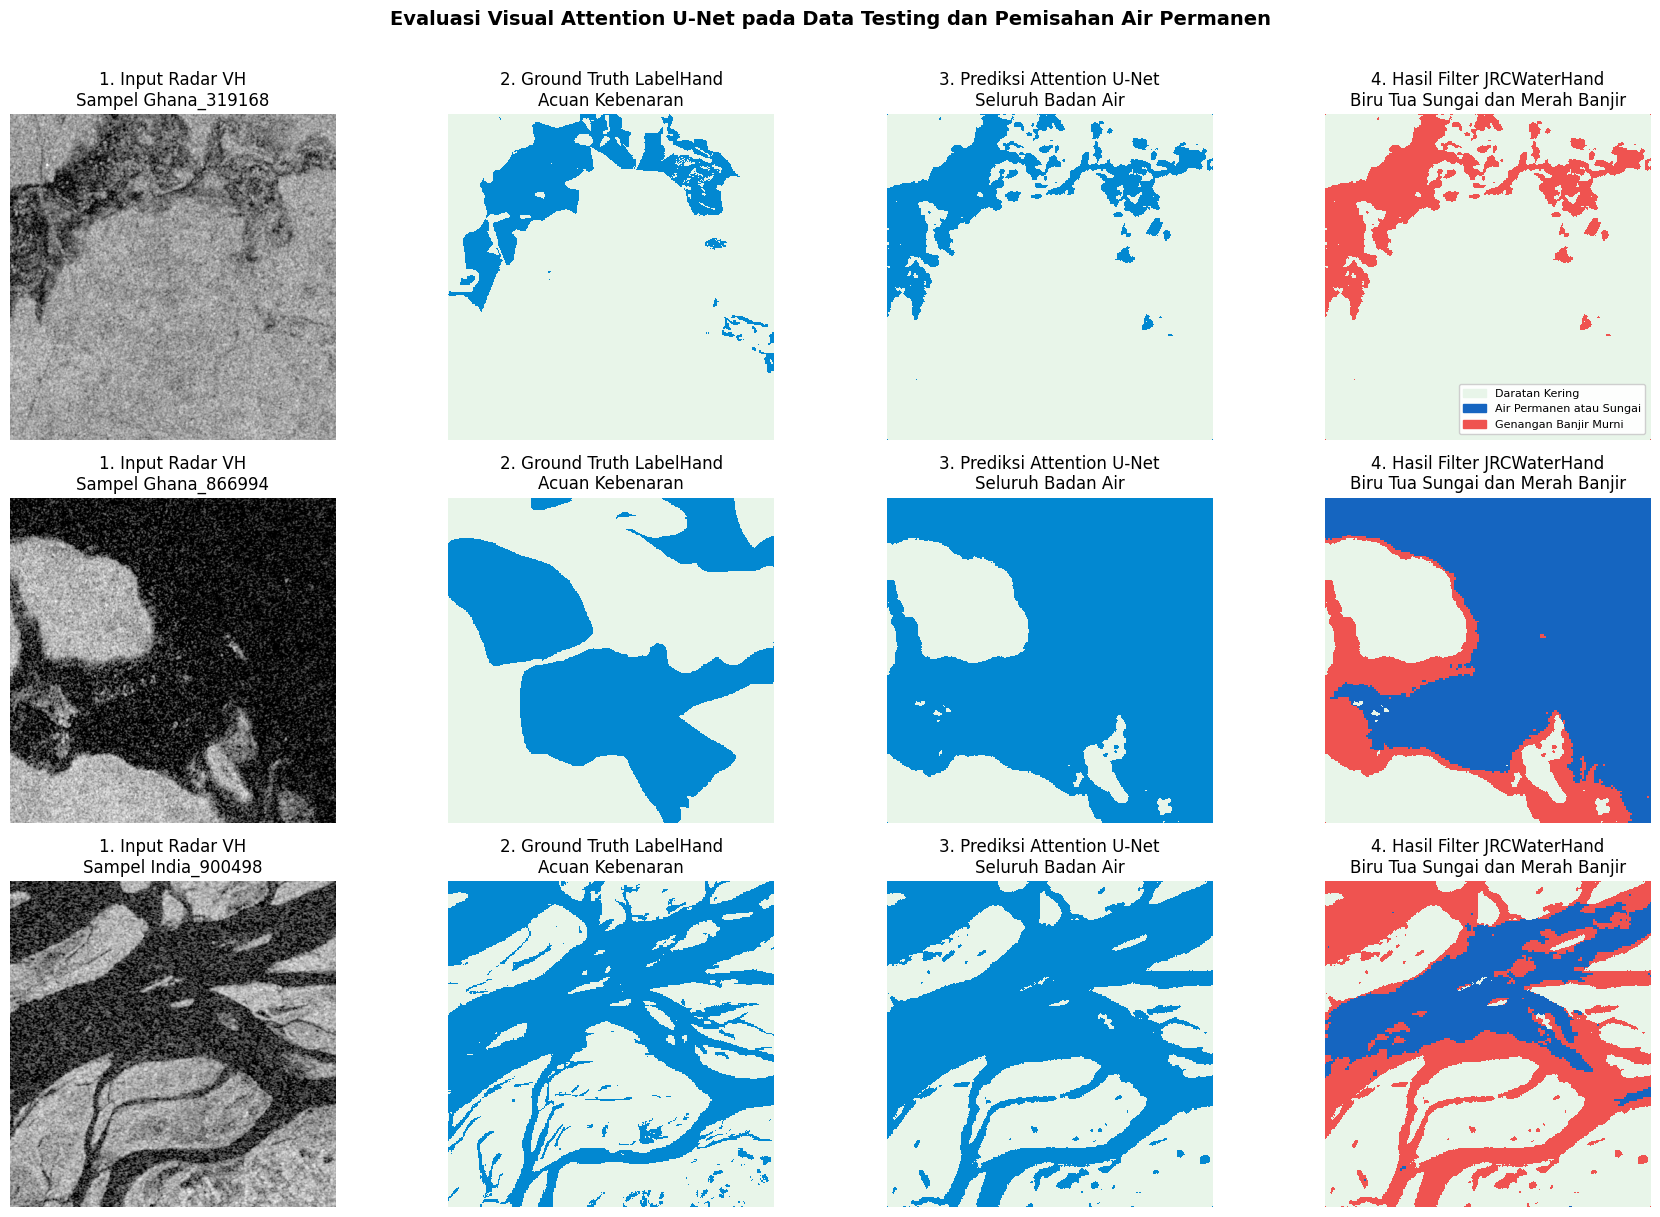

In [ ]:
import os
import torch
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches

# Memastikan model memakai bobot terbaik dari Epoch 7
model.load_state_dict(torch.load("/content/best_attention_unet_resnet34.pth"))
model.eval()

jrc_folder = "/content/sen1floods11/JRCWaterHand"

# Memilih 3 sampel dari Test Dataset yang memiliki area banjir signifikan
selected_test_indices = []
for i in range(len(test_dataset)):
    _, lbl, _ = test_dataset[i]
    water_ratio = (lbl == 1).sum().item() / lbl.numel()
    if 0.15 < water_ratio < 0.60:
        selected_test_indices.append(i)
    if len(selected_test_indices) == 3:
        break

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
fig.suptitle("Evaluasi Visual Attention U-Net pada Data Testing dan Pemisahan Air Permanen", fontsize=14, fontweight="bold", y=1.01)

cmap_seg = ListedColormap(["#e8f5e9", "#0288d1"])
cmap_flood_split = ListedColormap(["#e8f5e9", "#1565c0", "#ef5350"])

for row_idx, ds_idx in enumerate(selected_test_indices):
    img_tensor, lbl_tensor, chip_id = test_dataset[ds_idx]

    # Inferensi menggunakan GPU
    with torch.no_grad():
        logits = model(img_tensor.unsqueeze(0).to(device))
        pred_mask = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy()

    gt_mask = lbl_tensor.numpy()
    vh_band_display = img_tensor[1].numpy()

    # Membaca data air permanen JRCWaterHand untuk chip yang sama
    jrc_path = os.path.join(jrc_folder, f"{chip_id}_JRCWaterHand.tif")
    with rasterio.open(jrc_path) as src_jrc:
        perm_water = src_jrc.read(1)
        perm_water = np.nan_to_num(perm_water, nan=0).astype(np.int64)

    # Memisahkan hasil prediksi menjadi Air Permanen bernilai 1 dan Banjir Baru bernilai 2
    separated_map = np.zeros_like(pred_mask)
    separated_map[(pred_mask == 1) & (perm_water == 1)] = 1
    separated_map[(pred_mask == 1) & (perm_water == 0)] = 2

    # Mengabaikan area NoData pada visualisasi Ground Truth
    gt_clean = np.where(gt_mask == -1, 0, gt_mask)

    # Panel 1 Citra Radar VH
    axes[row_idx, 0].imshow(vh_band_display, cmap="gray")
    axes[row_idx, 0].set_title(f"1. Input Radar VH\nSampel {chip_id}")
    axes[row_idx, 0].axis("off")

    # Panel 2 Ground Truth Pakar
    axes[row_idx, 1].imshow(gt_clean, cmap=cmap_seg, vmin=0, vmax=1, interpolation="nearest")
    axes[row_idx, 1].set_title("2. Ground Truth LabelHand\nAcuan Kebenaran")
    axes[row_idx, 1].axis("off")

    # Panel 3 Prediksi Total Air oleh Attention U-Net
    axes[row_idx, 2].imshow(pred_mask, cmap=cmap_seg, vmin=0, vmax=1, interpolation="nearest")
    axes[row_idx, 2].set_title("3. Prediksi Attention U-Net\nSeluruh Badan Air")
    axes[row_idx, 2].axis("off")

    # Panel 4 Pemisahan Sungai Permanen vs Genangan Banjir Murni
    axes[row_idx, 3].imshow(separated_map, cmap=cmap_flood_split, vmin=0, vmax=2, interpolation="nearest")
    axes[row_idx, 3].set_title("4. Hasil Filter JRCWaterHand\nBiru Tua Sungai dan Merah Banjir")
    axes[row_idx, 3].axis("off")

    if row_idx == 0:
        patches = [
            mpatches.Patch(color="#e8f5e9", label="Daratan Kering"),
            mpatches.Patch(color="#1565c0", label="Air Permanen atau Sungai"),
            mpatches.Patch(color="#ef5350", label="Genangan Banjir Murni")
        ]
        axes[row_idx, 3].legend(handles=patches, loc="lower right", fontsize=8, framealpha=0.95)

plt.tight_layout()
plt.show()


In [ ]:
import json
import rasterio
from rasterio.features import shapes
from rasterio.warp import transform_geom

# Mengambil sampel pertama dari daftar pengujian tadi
sample_idx = selected_test_indices[0]
img_tensor, _, chip_id = test_dataset[sample_idx]

s1_raw_path = os.path.join(s1_folder, f"{chip_id}_S1Hand.tif")
jrc_raw_path = os.path.join(jrc_folder, f"{chip_id}_JRCWaterHand.tif")

# 1. Jalankan prediksi model
with torch.no_grad():
    logits = model(img_tensor.unsqueeze(0).to(device))
    pred_mask = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy().astype(np.uint8)

# 2. Ambil hanya genangan banjir baru di luar sungai permanen
with rasterio.open(jrc_raw_path) as src_jrc:
    perm_water = np.nan_to_num(src_jrc.read(1), nan=0).astype(np.uint8)

pure_flood_mask = ((pred_mask == 1) & (perm_water == 0)).astype(np.uint8)

# 3. Ekstraksi piksel banjir menjadi poligon vektor berkoordinat EPSG 4326
features = []
with rasterio.open(s1_raw_path) as src:
    transform_matrix = src.transform
    source_crs = src.crs

    # Mengubah kumpulan piksel bernilai 1 menjadi geometri poligon
    for geom, val in shapes(pure_flood_mask, mask=(pure_flood_mask == 1), transform=transform_matrix):
        if val == 1:
            # Konversi sistem koordinat ke standar GPS WebGIS EPSG 4326
            geom_wgs84 = transform_geom(source_crs, "EPSG:4326", geom)
            features.append({
                "type": "Feature",
                "properties": {
                    "chip_id": chip_id,
                    "class": "inundated_flood"
                },
                "geometry": geom_wgs84
            })

geojson_output = {
    "type": "FeatureCollection",
    "features": features
}

output_geojson_path = f"/content/{chip_id}_flood_polygons.geojson"
with open(output_geojson_path, "w") as f:
    json.dump(geojson_output, f)

print("Konversi Raster ke Vektor Selesai")
print(f"Lokasi Sampel {chip_id}")
print(f"Jumlah Poligon Genangan Banjir Terbentuk {len(features)} poligon")
print(f"File GeoJSON tersimpan di {output_geojson_path}")


Konversi Raster ke Vektor Selesai
Lokasi Sampel Ghana_319168
Jumlah Poligon Genangan Banjir Terbentuk 83 poligon
File GeoJSON tersimpan di /content/Ghana_319168_flood_polygons.geojson


In [ ]:
from google.colab import files

# Mengunduh bobot model terbaik dan poligon hasil ekstraksi ke komputer lokal
files.download("/content/best_attention_unet_resnet34.pth")
files.download(output_geojson_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

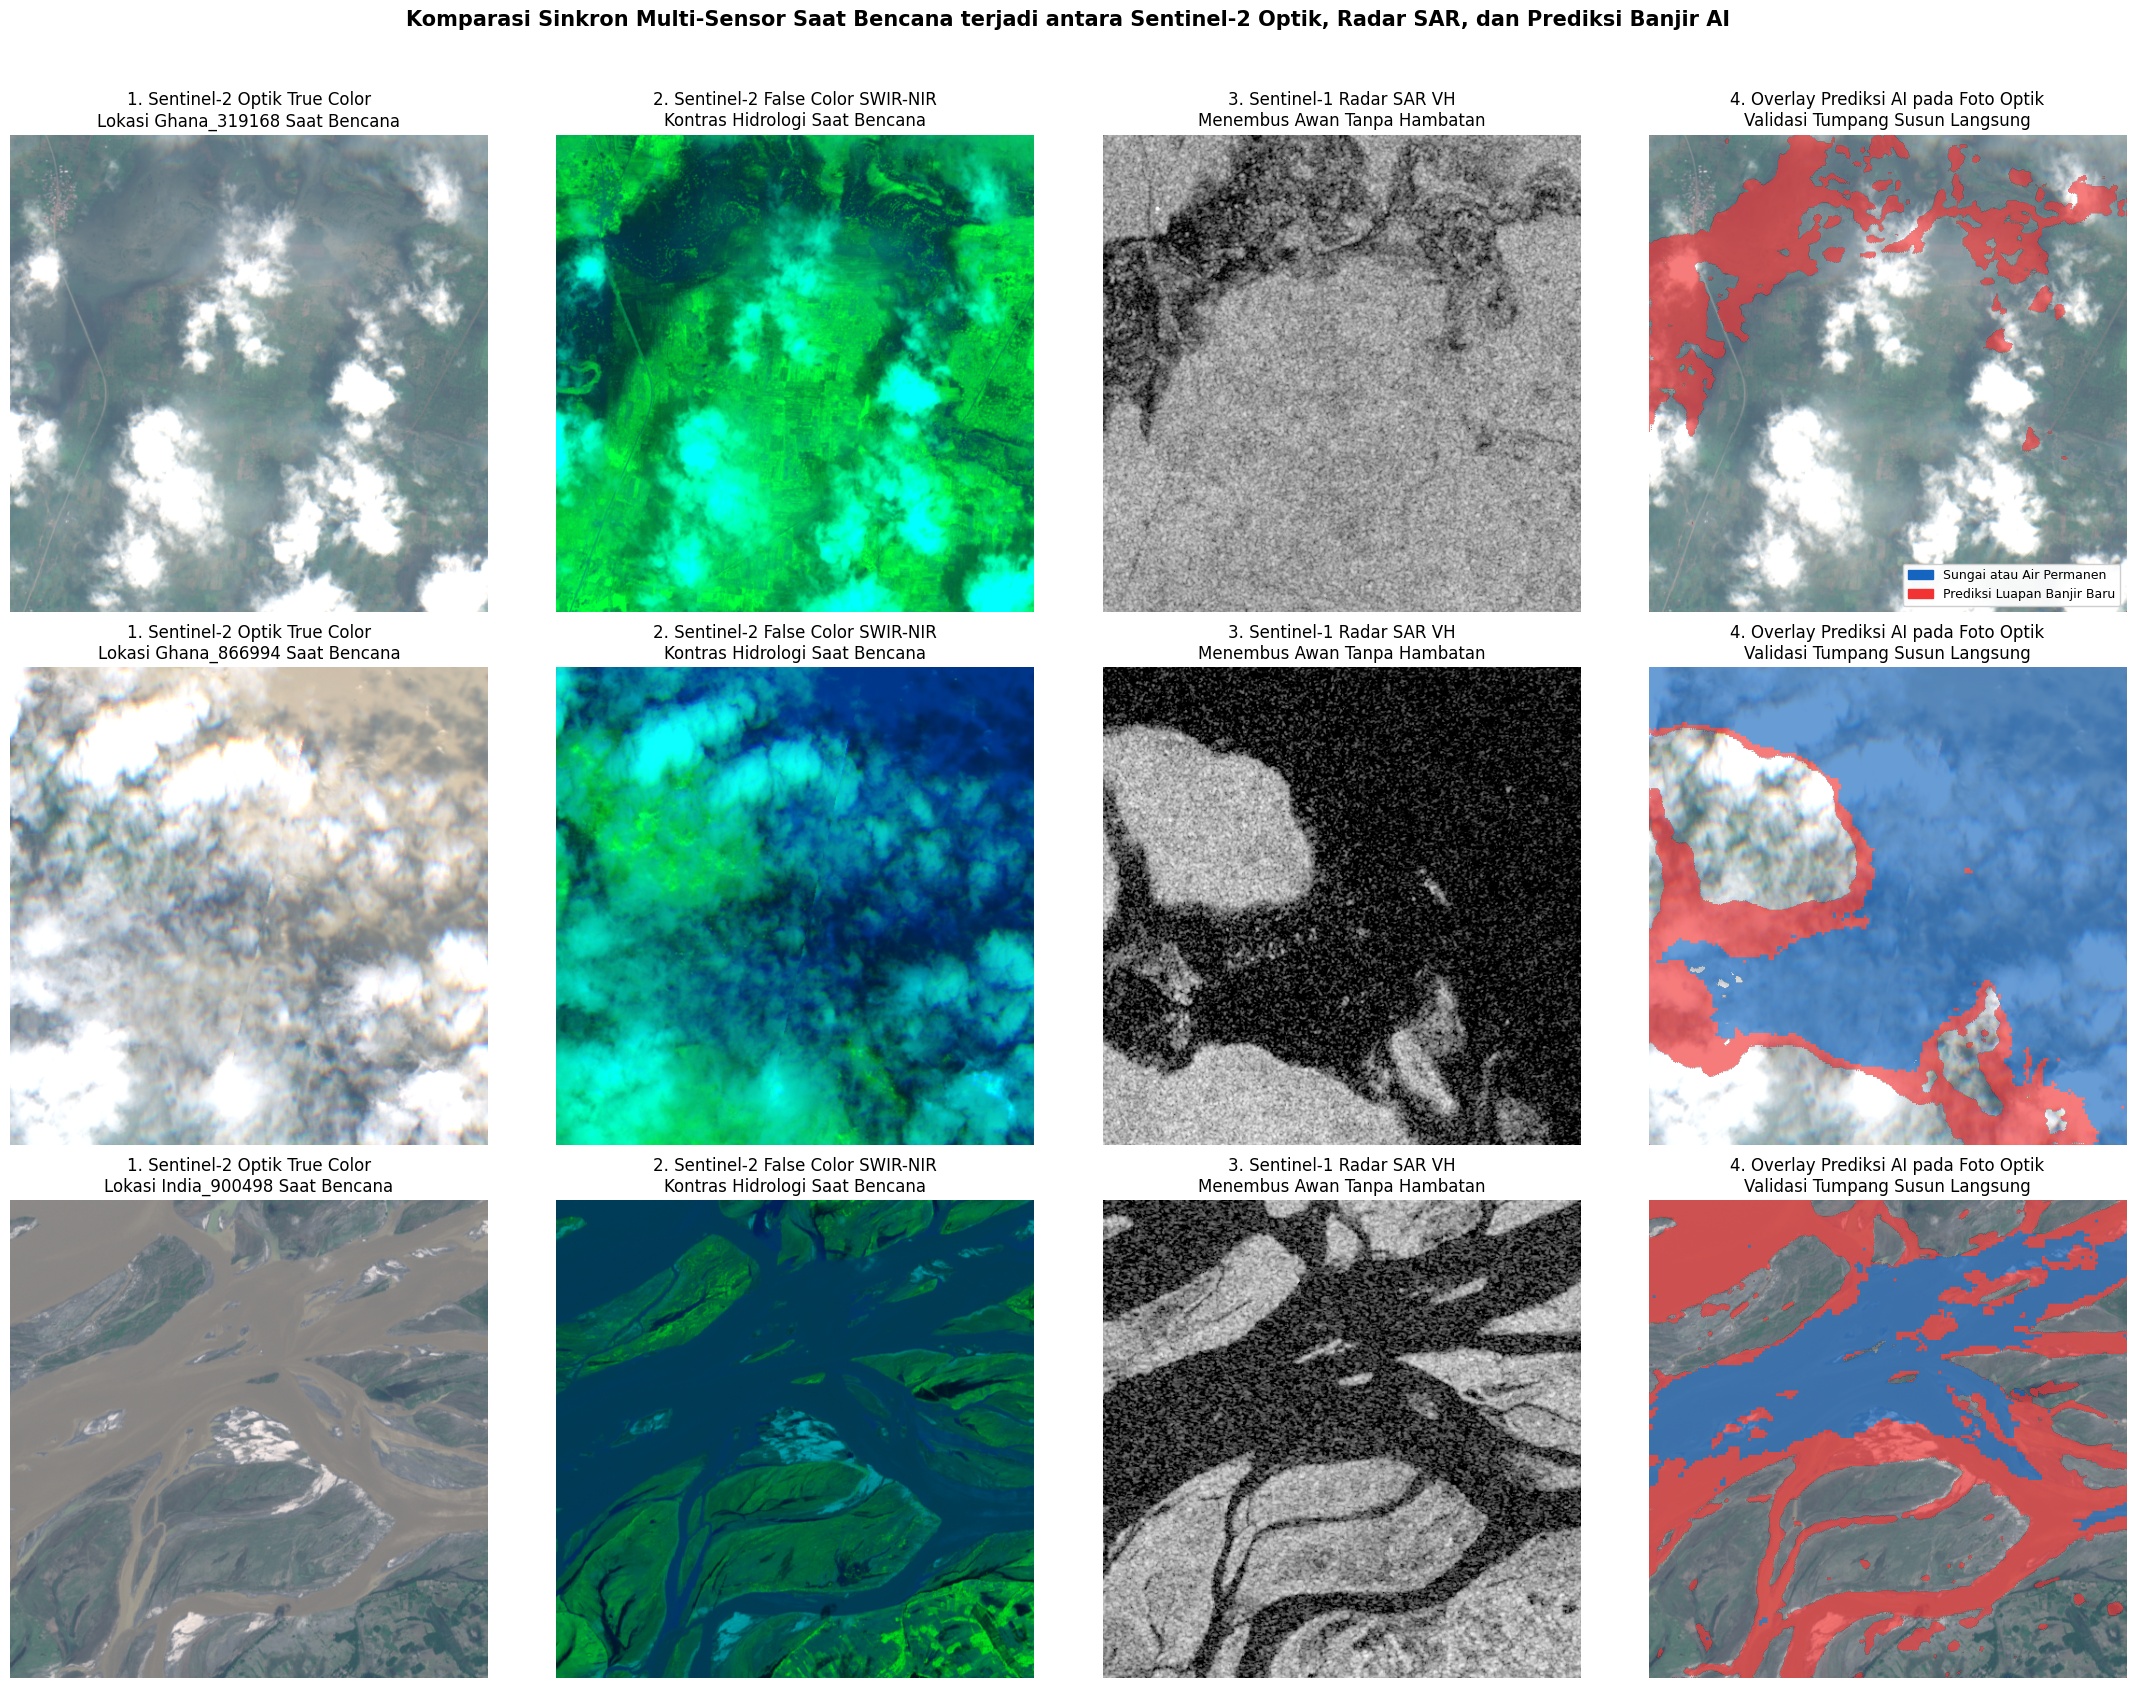

In [ ]:
import os
import subprocess
import numpy as np
import rasterio
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches

# 1. Konfigurasi direktori
s1_dir = "/content/sen1floods11/S1Hand"
s2_dir = "/content/sen1floods11/S2Hand"
jrc_dir = "/content/sen1floods11/JRCWaterHand"
os.makedirs(s2_dir, exist_ok=True)

# Memakai 3 sampel pengujian yang sama agar pembahasannya berkesinambungan
target_indices = selected_test_indices[:3] if "selected_test_indices" in globals() else [0, 1, 2]

fig, axes = plt.subplots(len(target_indices), 4, figsize=(22, 5.5 * len(target_indices)))
fig.suptitle(
    "Komparasi Sinkron Multi-Sensor Saat Bencana terjadi antara Sentinel-2 Optik, Radar SAR, dan Prediksi Banjir AI",
    fontsize=15,
    fontweight="bold",
    y=1.02
)

for row_idx, ds_idx in enumerate(target_indices):
    img_tensor, lbl_tensor, chip_id = test_dataset[ds_idx]

    s2_path = os.path.join(s2_dir, f"{chip_id}_S2Hand.tif")
    jrc_path = os.path.join(jrc_dir, f"{chip_id}_JRCWaterHand.tif")

    # Unduh citra Sentinel-2 waktu bencana yang sama jika belum ada di disk
    if not os.path.exists(s2_path):
        gcs_s2 = f"gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S2Hand/{chip_id}_S2Hand.tif"
        subprocess.run(["gsutil", "-q", "cp", gcs_s2, s2_path], check=False)

    # Membaca band optik Sentinel-2
    # Urutan band pada S2Hand yaitu B2=2 (Biru), B3=3 (Hijau), B4=4 (Merah), B8=8 (NIR), B11=11 (SWIR)
    with rasterio.open(s2_path) as src_s2:
        blue = src_s2.read(2).astype(np.float32)
        green = src_s2.read(3).astype(np.float32)
        red = src_s2.read(4).astype(np.float32)
        nir = src_s2.read(8).astype(np.float32)
        swir = src_s2.read(11).astype(np.float32)

    # Menyusun foto True Color RGB dengan peningkatan kecerahan
    rgb_true = np.dstack((red, green, blue))
    rgb_true = np.nan_to_num(rgb_true, nan=0.0)
    rgb_true = np.clip(rgb_true / 2800.0, 0, 1)
    rgb_true = np.power(rgb_true, 0.85) # Koreksi gamma agar detail permukaan bumi lebih terang

    # Menyusun foto False Color SWIR-NIR-Red (Standar Hidrologi)
    # Pada kombinasi ini, air tampak biru tua/hitam pekat, vegetasi hijau cerah, dan awan tampak putih/cyan
    false_color = np.dstack((swir, nir, red))
    false_color = np.nan_to_num(false_color, nan=0.0)
    false_color = np.clip(false_color / 4000.0, 0, 1)

    # Menjalankan prediksi model Attention U-Net
    with torch.no_grad():
        logits = model(img_tensor.unsqueeze(0).to(device))
        pred_mask = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy()

    # Membaca data air permanen untuk memisahkan sungai dan banjir
    with rasterio.open(jrc_path) as src_jrc:
        perm_water = np.nan_to_num(src_jrc.read(1), nan=0).astype(np.int64)

    vh_radar = img_tensor[1].numpy()

    # Panel 1 Foto Kamera Optik Sentinel-2 True Color RGB
    axes[row_idx, 0].imshow(rgb_true)
    axes[row_idx, 0].set_title(f"1. Sentinel-2 Optik True Color\nLokasi {chip_id} Saat Bencana")
    axes[row_idx, 0].axis("off")

    # Panel 2 Foto Sentinel-2 False Color (SWIR-NIR-Red)
    axes[row_idx, 1].imshow(false_color)
    axes[row_idx, 1].set_title("2. Sentinel-2 False Color SWIR-NIR\nKontras Hidrologi Saat Bencana")
    axes[row_idx, 1].axis("off")

    # Panel 3 Citra Radar Sentinel-1 VH
    axes[row_idx, 2].imshow(vh_radar, cmap="gray")
    axes[row_idx, 2].set_title("3. Sentinel-1 Radar SAR VH\nMenembus Awan Tanpa Hambatan")
    axes[row_idx, 2].axis("off")

    # Panel 4 Overlay Prediksi AI di Atas Foto Optik Sentinel-2
    axes[row_idx, 3].imshow(rgb_true)

    # Membuat lapisan warna transparan untuk Sungai Permanen (Biru) dan Banjir Baru (Merah)
    overlay_rgba = np.zeros((pred_mask.shape[0], pred_mask.shape[1], 4), dtype=np.float32)

    # Warna Biru untuk sungai permanen
    is_perm = (pred_mask == 1) & (perm_water == 1)
    overlay_rgba[is_perm] = [0.08, 0.40, 0.75, 0.65]

    # Warna Merah Terang untuk genangan banjir murni
    is_flood = (pred_mask == 1) & (perm_water == 0)
    overlay_rgba[is_flood] = [0.95, 0.20, 0.20, 0.65]

    axes[row_idx, 3].imshow(overlay_rgba)
    axes[row_idx, 3].set_title("4. Overlay Prediksi AI pada Foto Optik\nValidasi Tumpang Susun Langsung")
    axes[row_idx, 3].axis("off")

    if row_idx == 0:
        patches = [
            mpatches.Patch(color="#1565c0", label="Sungai atau Air Permanen"),
            mpatches.Patch(color="#f23333", label="Prediksi Luapan Banjir Baru")
        ]
        axes[row_idx, 3].legend(handles=patches, loc="lower right", fontsize=9, framealpha=0.95)

plt.tight_layout()
plt.show()


In [ ]:
# 1. Reset seed ke 42 agar kondisi awal bobot dan urutan batch identik dengan eksperimen sebelumnya
set_seed(42)

# 2. Inisialisasi Model Baseline Standard U-Net dengan mematikan Attention Gate
baseline_model = ResNet34UNet(num_classes=2, use_attention=False).to(device)
criterion = MaskedCombinedLoss(ignore_index=-1)
optimizer_base = torch.optim.AdamW(baseline_model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler_base = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_base, mode="max", factor=0.5, patience=3)

num_epochs = 15
best_val_iou_base = 0.0
baseline_save_path = "/content/best_standard_unet_resnet34.pth"

# Menyimpan riwayat pelatihan untuk grafik Bab 4
history_base = {"train_loss": [], "val_loss": [], "val_iou": [], "val_f1": []}

print("Memulai pelatihan Baseline Standard U-Net ResNet-34 tanpa Attention Gate")
for epoch in range(1, num_epochs + 1):
    t_loss, t_iou, t_f1, _, _ = run_epoch(baseline_model, train_loader, criterion, optimizer_base)
    v_loss, v_iou, v_f1, v_prec, v_rec = run_epoch(baseline_model, val_loader, criterion, optimizer=None)

    scheduler_base.step(v_iou)

    history_base["train_loss"].append(t_loss)
    history_base["val_loss"].append(v_loss)
    history_base["val_iou"].append(v_iou * 100)
    history_base["val_f1"].append(v_f1 * 100)

    if v_iou > best_val_iou_base:
        best_val_iou_base = v_iou
        torch.save(baseline_model.state_dict(), baseline_save_path)
        status_simpan = "Bobot Terbaik Disimpan"
    else:
        status_simpan = ""

    print(
        f"Epoch {epoch:02d}/{num_epochs:02d} | "
        f"Train Loss {t_loss:.4f} | Train IoU {t_iou*100:.2f}% | "
        f"Val Loss {v_loss:.4f} | Val IoU {v_iou*100:.2f}% | Val F1 {v_f1*100:.2f}% {status_simpan}"
    )

# 3. Evaluasi Akhir Model Baseline pada Data Testing
print("\nMemuat bobot terbaik Standard U-Net untuk evaluasi pada Test Split resmi")
baseline_model.load_state_dict(torch.load(baseline_save_path))
base_test_loss, base_test_iou, base_test_f1, base_test_prec, base_test_rec = run_epoch(
    baseline_model, test_loader, criterion, optimizer=None
)

print("\nHasil Evaluasi Akhir Data Testing untuk Standard U-Net")
print(f"Water IoU mencapai {base_test_iou*100:.2f}%")
print(f"F1-Score mencapai {base_test_f1*100:.2f}%")
print(f"Precision mencapai {base_test_prec*100:.2f}%")
print(f"Recall mencapai {base_test_rec*100:.2f}%")


Memulai pelatihan Baseline Standard U-Net ResNet-34 tanpa Attention Gate
Epoch 01/15 | Train Loss 0.6181 | Train IoU 41.68% | Val Loss 0.6280 | Val IoU 32.41% | Val F1 48.95% Bobot Terbaik Disimpan
Epoch 02/15 | Train Loss 0.5690 | Train IoU 48.06% | Val Loss 0.5233 | Val IoU 50.76% | Val F1 67.34% Bobot Terbaik Disimpan
Epoch 03/15 | Train Loss 0.5473 | Train IoU 49.90% | Val Loss 0.4870 | Val IoU 59.00% | Val F1 74.21% Bobot Terbaik Disimpan
Epoch 04/15 | Train Loss 0.5267 | Train IoU 54.21% | Val Loss 0.4502 | Val IoU 63.11% | Val F1 77.38% Bobot Terbaik Disimpan
Epoch 05/15 | Train Loss 0.5223 | Train IoU 52.38% | Val Loss 0.5075 | Val IoU 49.09% | Val F1 65.85% 
Epoch 06/15 | Train Loss 0.5052 | Train IoU 54.09% | Val Loss 0.4767 | Val IoU 57.89% | Val F1 73.33% 
Epoch 07/15 | Train Loss 0.5030 | Train IoU 54.56% | Val Loss 0.4605 | Val IoU 62.22% | Val F1 76.71% 
Epoch 08/15 | Train Loss 0.4878 | Train IoU 58.45% | Val Loss 0.5413 | Val IoU 39.39% | Val F1 56.52% 
Epoch 09/15 | T

TABEL KOMPARASI PERFORMA MODEL PADA DATA TESTING SEN1FLOODS11
    Metrik Evaluasi Standard U-Net ResNet-34 (Baseline) Attention U-Net ResNet-34 (Proposed) Selisih Peningkatan
      Water IoU (%)                               67.06                                63.71              -3.35%
F1-Score / Dice (%)                               80.29                                77.83              -2.45%
      Precision (%)                               76.66                                73.31              -3.36%
         Recall (%)                               84.27                                82.96              -1.31%
   Jumlah Parameter                          24,451,618                           24,543,534      +91,916 params


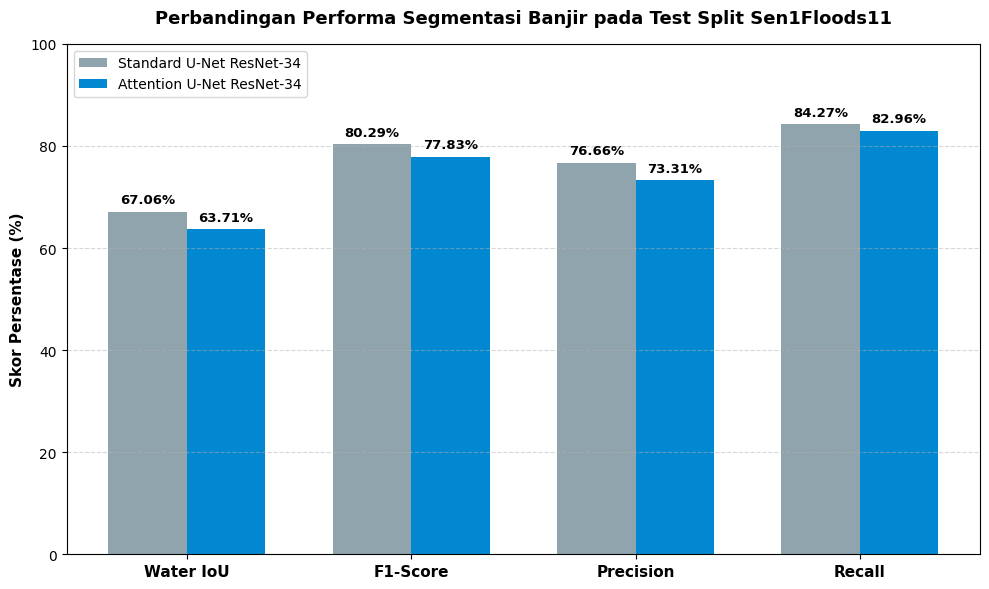

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Memastikan kedua model memuat bobot terbaik masing-masing
proposed_model = ResNet34UNet(num_classes=2, use_attention=True).to(device)
proposed_model.load_state_dict(torch.load("/content/best_attention_unet_resnet34.pth"))
proposed_model.eval()

baseline_model = ResNet34UNet(num_classes=2, use_attention=False).to(device)
baseline_model.load_state_dict(torch.load("/content/best_standard_unet_resnet34.pth"))
baseline_model.eval()

# 2. Evaluasi ulang pada Test Split untuk memastikan angka presisi
_, base_iou, base_f1, base_prec, base_rec = run_epoch(baseline_model, test_loader, criterion, optimizer=None)
_, att_iou, att_f1, att_prec, att_rec = run_epoch(proposed_model, test_loader, criterion, optimizer=None)

# Menghitung jumlah parameter masing-masing model
params_base = sum(p.numel() for p in baseline_model.parameters() if p.requires_grad)
params_att = sum(p.numel() for p in proposed_model.parameters() if p.requires_grad)

# 3. Menyusun DataFrame Perbandingan Bab 4
comparison_df = pd.DataFrame({
    "Metrik Evaluasi": [
        "Water IoU (%)",
        "F1-Score / Dice (%)",
        "Precision (%)",
        "Recall (%)",
        "Jumlah Parameter"
    ],
    "Standard U-Net ResNet-34 (Baseline)": [
        round(base_iou * 100, 2),
        round(base_f1 * 100, 2),
        round(base_prec * 100, 2),
        round(base_rec * 100, 2),
        f"{params_base:,}"
    ],
    "Attention U-Net ResNet-34 (Proposed)": [
        round(att_iou * 100, 2),
        round(att_f1 * 100, 2),
        round(att_prec * 100, 2),
        round(att_rec * 100, 2),
        f"{params_att:,}"
    ],
    "Selisih Peningkatan": [
        f"{(att_iou - base_iou)*100:+.2f}%",
        f"{(att_f1 - base_f1)*100:+.2f}%",
        f"{(att_prec - base_prec)*100:+.2f}%",
        f"{(att_rec - base_rec)*100:+.2f}%",
        f"+{params_att - params_base:,} params"
    ]
})

print("TABEL KOMPARASI PERFORMA MODEL PADA DATA TESTING SEN1FLOODS11")
print(comparison_df.to_string(index=False))

# Simpan tabel ke CSV agar mudah disalin ke Microsoft Word atau LaTeX
comparison_df.to_csv("/content/tabel_komparasi_bab4.csv", index=False)

# 4. Visualisasi Grafik Batang Perbandingan Metrik
metrics_names = ["Water IoU", "F1-Score", "Precision", "Recall"]
base_scores = [base_iou * 100, base_f1 * 100, base_prec * 100, base_rec * 100]
att_scores = [att_iou * 100, att_f1 * 100, att_prec * 100, att_rec * 100]

x = np.arange(len(metrics_names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, base_scores, width, label="Standard U-Net ResNet-34", color="#90a4ae")
rects2 = ax.bar(x + width/2, att_scores, width, label="Attention U-Net ResNet-34", color="#0288d1")

ax.set_ylabel("Skor Persentase (%)", fontsize=11, fontweight="bold")
ax.set_title("Perbandingan Performa Segmentasi Banjir pada Test Split Sen1Floods11", fontsize=13, fontweight="bold", pad=15)
ax.set_xticks(x)
ax.set_xticklabels(metrics_names, fontsize=11, fontweight="bold")
ax.set_ylim(0, 100)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(fontsize=10, loc="upper left")

# Menambahkan label angka di atas setiap batang
for rect in rects1 + rects2:
    height = rect.get_height()
    ax.annotate(
        f"{height:.2f}%",
        xy=(rect.get_x() + rect.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold"
    )

plt.tight_layout()
plt.savefig("/content/grafik_komparasi_model_bab4.png", dpi=300)
plt.show()


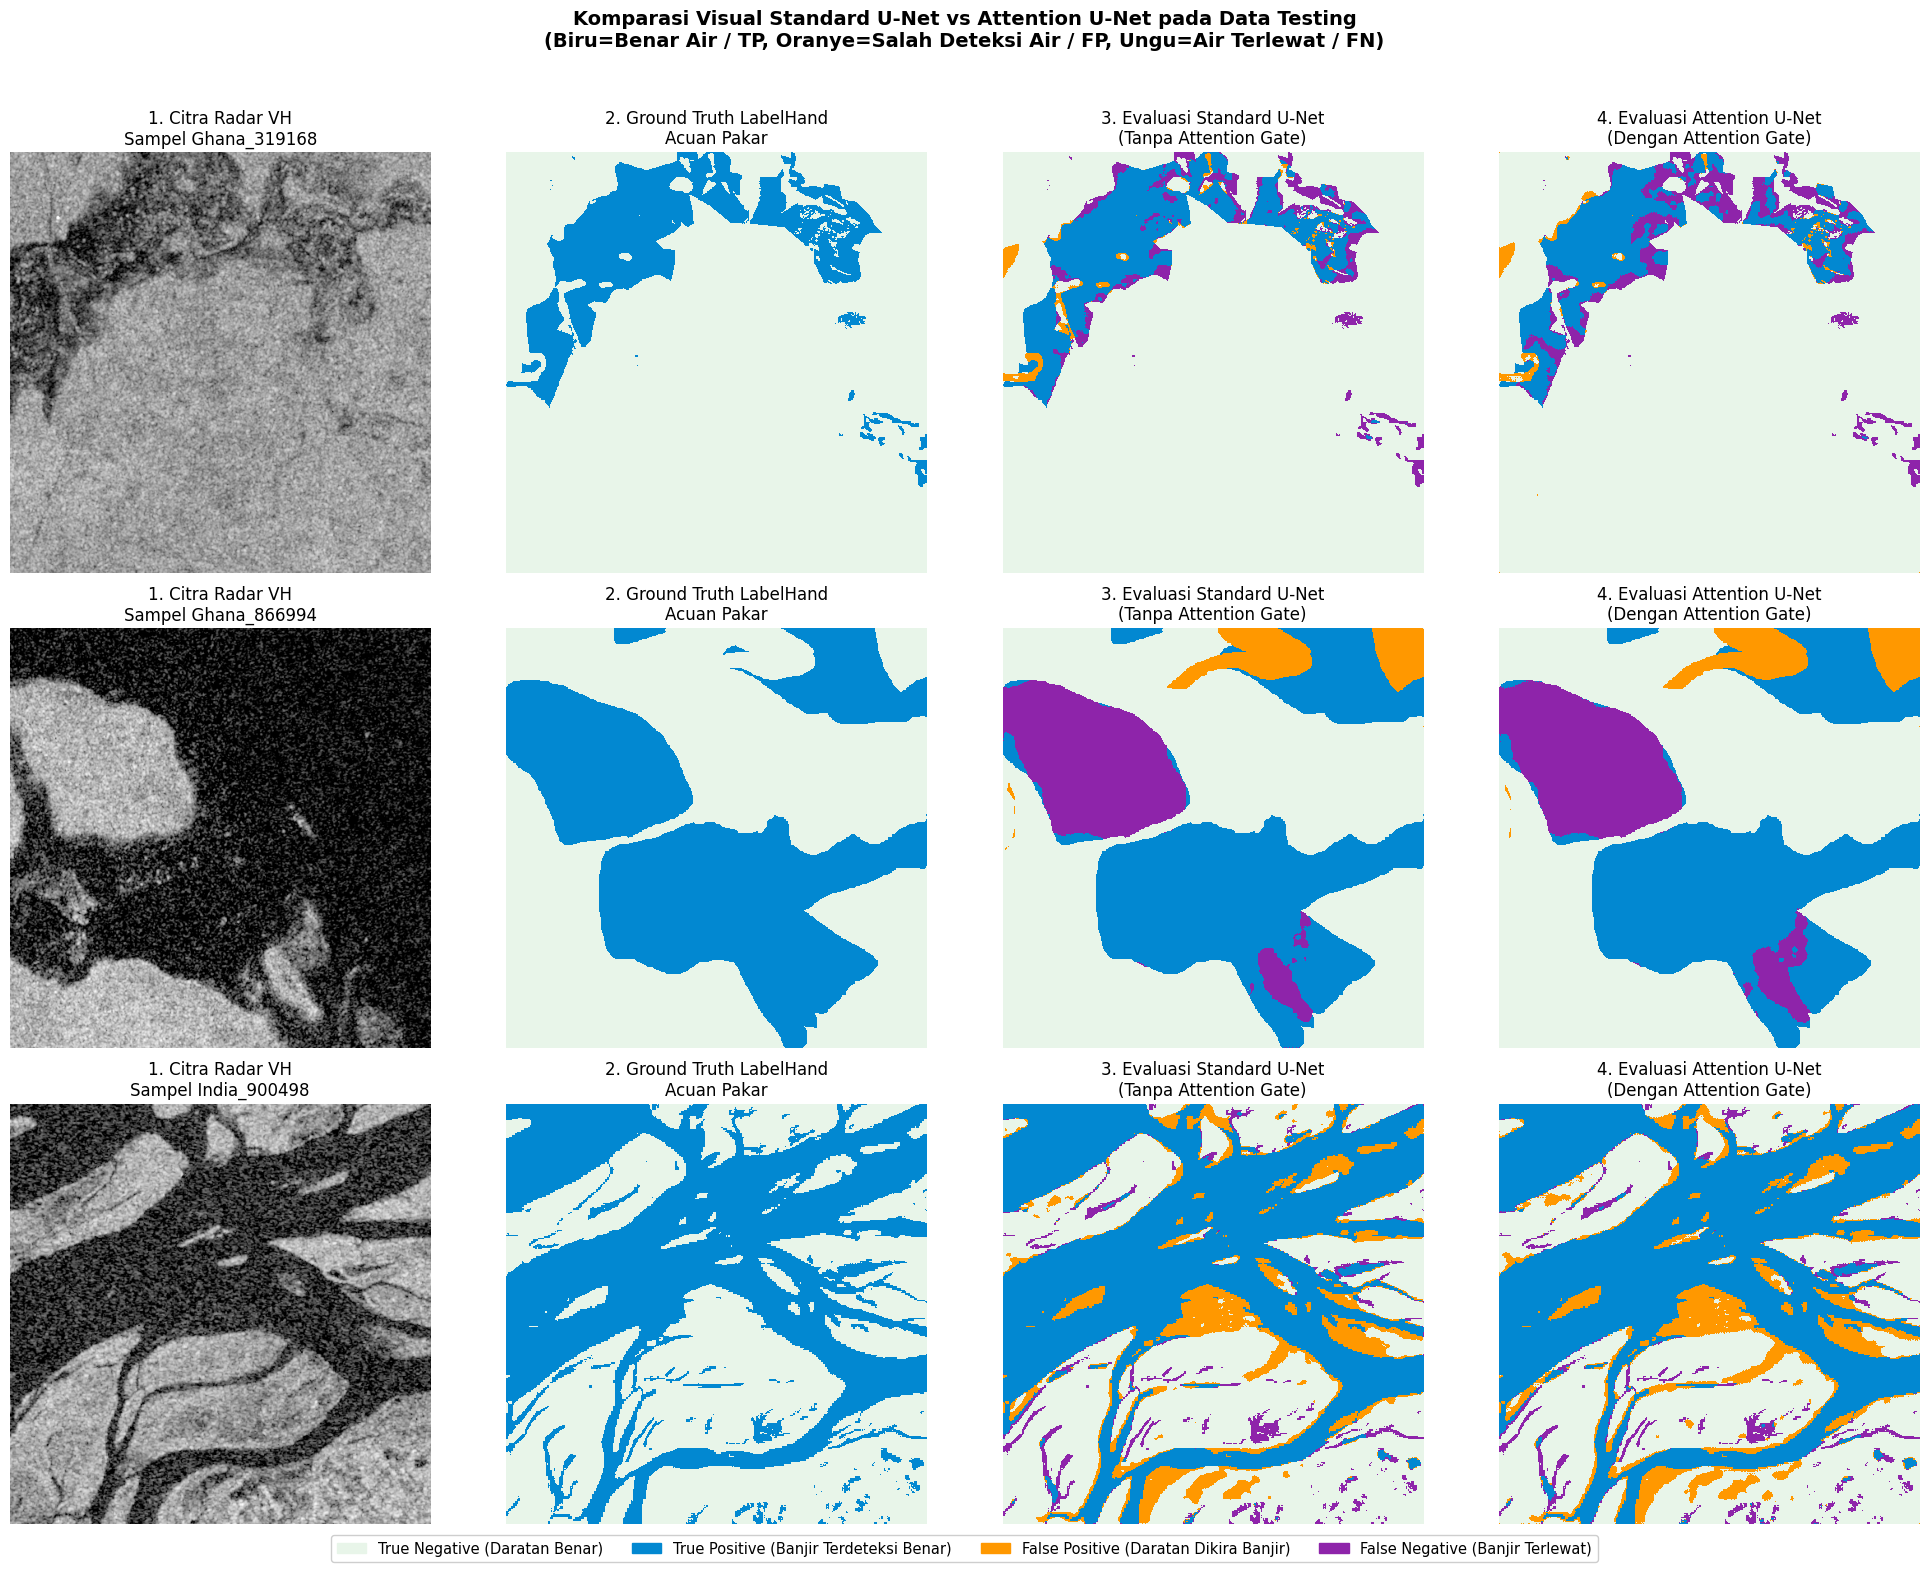

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches

target_indices = selected_test_indices[:3] if "selected_test_indices" in globals() else [0, 1, 2]

fig, axes = plt.subplots(len(target_indices), 4, figsize=(20, 5 * len(target_indices)))
fig.suptitle(
    "Komparasi Visual Standard U-Net vs Attention U-Net pada Data Testing\n"
    "(Biru=Benar Air / TP, Oranye=Salah Deteksi Air / FP, Ungu=Air Terlewat / FN)",
    fontsize=14,
    fontweight="bold",
    y=1.02
)

# Skema warna peta evaluasi error:
# 0: Daratan Benar (Hijau Muda), 1: Air Benar / TP (Biru), 2: Salah Deteksi Air / FP (Oranye), 3: Air Terlewat / FN (Ungu)
cmap_eval = ListedColormap(["#e8f5e9", "#0288d1", "#ff9800", "#8e24aa"])

def build_error_map(pred, gt):
    err_map = np.zeros_like(pred)
    valid = (gt != -1)
    err_map[valid & (pred == 1) & (gt == 1)] = 1 # True Positive
    err_map[valid & (pred == 1) & (gt == 0)] = 2 # False Positive (Noise daratan dikira banjir)
    err_map[valid & (pred == 0) & (gt == 1)] = 3 # False Negative (Banjir gagal terdeteksi)
    return err_map

for row_idx, ds_idx in enumerate(target_indices):
    img_tensor, lbl_tensor, chip_id = test_dataset[ds_idx]
    gt_mask = lbl_tensor.numpy()
    gt_clean = np.where(gt_mask == -1, 0, gt_mask)
    vh_band = img_tensor[1].numpy()

    with torch.no_grad():
        inp = img_tensor.unsqueeze(0).to(device)
        pred_base = torch.argmax(baseline_model(inp), dim=1).squeeze(0).cpu().numpy()
        pred_att = torch.argmax(proposed_model(inp), dim=1).squeeze(0).cpu().numpy()

    err_base = build_error_map(pred_base, gt_mask)
    err_att = build_error_map(pred_att, gt_mask)

    # Panel 1 Input Radar VH
    axes[row_idx, 0].imshow(vh_band, cmap="gray")
    axes[row_idx, 0].set_title(f"1. Citra Radar VH\nSampel {chip_id}")
    axes[row_idx, 0].axis("off")

    # Panel 2 Ground Truth
    axes[row_idx, 1].imshow(gt_clean, cmap=ListedColormap(["#e8f5e9", "#0288d1"]), vmin=0, vmax=1, interpolation="nearest")
    axes[row_idx, 1].set_title("2. Ground Truth LabelHand\nAcuan Pakar")
    axes[row_idx, 1].axis("off")

    # Panel 3 Peta Evaluasi Standard U-Net
    axes[row_idx, 2].imshow(err_base, cmap=cmap_eval, vmin=0, vmax=3, interpolation="nearest")
    axes[row_idx, 2].set_title("3. Evaluasi Standard U-Net\n(Tanpa Attention Gate)")
    axes[row_idx, 2].axis("off")

    # Panel 4 Peta Evaluasi Attention U-Net
    axes[row_idx, 3].imshow(err_att, cmap=cmap_eval, vmin=0, vmax=3, interpolation="nearest")
    axes[row_idx, 3].set_title("4. Evaluasi Attention U-Net\n(Dengan Attention Gate)")
    axes[row_idx, 3].axis("off")

patches = [
    mpatches.Patch(color="#e8f5e9", label="True Negative (Daratan Benar)"),
    mpatches.Patch(color="#0288d1", label="True Positive (Banjir Terdeteksi Benar)"),
    mpatches.Patch(color="#ff9800", label="False Positive (Daratan Dikira Banjir)"),
    mpatches.Patch(color="#8e24aa", label="False Negative (Banjir Terlewat)")
]
fig.legend(handles=patches, loc="lower center", ncol=4, fontsize=10.5, framealpha=0.95, bbox_to_anchor=(0.5, -0.02))

plt.tight_layout()
plt.savefig("/content/komparasi_visual_error_bab4.png", dpi=300, bbox_inches="tight")
plt.show()
